# 01 — Data Exploration & Preprocessing

This notebook loads the HARD dataset from the project folder, explores and cleans the reviews, creates labels from the star ratings, splits the data into training, validation, and test sets, and converts the text into numerical Bag-of-Words features. No model training is performed in this notebook.

Run the notebook from the `notebooks/` folder or the project root. The dataset file should be located at:

`data/HARD-Arabic-Dataset-master/data/unbalanced-reviews.txt`

The processed files will be saved in:

`data/processed/`

The labels are assigned as follows: ratings 1–2 are Negative, rating 3 is Neutral, and ratings 4–5 are Positive. These labels are derived from star ratings; they are not manually annotated sentiment labels.

## 1. Requirements

If you encounter a `ModuleNotFoundError`, run the following command in the terminal for the same Python environment used by Jupyter, then restart the kernel.

In [4]:
# %pip install pandas numpy matplotlib scikit-learn scipy joblib

Note: you may need to restart the kernel to use updated packages.


In [10]:
from pathlib import Path
import csv
import json
import re
import unicodedata

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.sparse import save_npz
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

SEED = 42
TEST_SIZE = 0.10
VALIDATION_SIZE = 0.10
MAX_FEATURES = 8000
LABEL_MAP = {0: "negative", 1: "neutral", 2: "positive"}

cwd = Path.cwd().resolve()
project_candidates = [cwd, *cwd.parents]
project_dir = next(
    (path for path in project_candidates if (path / "data").is_dir()),
    cwd
)

raw_candidates = [
    project_dir / "data" / "HARD-Arabic-Dataset-master" / "data" / "unbalanced-reviews.txt",
    project_dir / "data" / "HARD-Arabic-Dataset-master" / "unbalanced-reviews.txt",
]

raw_path = next((path for path in raw_candidates if path.exists()), None)

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_dir)
print("Processed output:", processed_dir)

if raw_path is None:
    raise FileNotFoundError(
        "Could not find unbalanced-reviews.txt. "
        "Check that the folder structure matches the expected layout, "
        "or update raw_candidates to match the dataset location."
    )

print("Dataset found:", raw_path)

Project folder: E:\ANN\ANN_01
Processed output: E:\ANN\ANN_01\data\processed
Dataset found: E:\ANN\ANN_01\data\HARD-Arabic-Dataset-master\data\unbalanced-reviews.txt


## 2. Reading the HARD Dataset

The file is expected to be tab-separated and to contain no header, with the following columns: `rating`, `review_id`, `hotel_id`, `user_id`, `no_nights`, and `review`. The code also handles a header row if one is present.

In [11]:
columns = [
    "review_no",
    "hotel_name",
    "rating",
    "user_type",
    "room_type",
    "no_nights",
    "text",
]

records = []
bad_lines = 0

with raw_path.open("r", encoding="utf-16", errors="replace", newline="") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if not row or not any(value.strip() for value in row):
            continue

        # Skip the header row.
        if len(row) >= 3 and row[2].strip().lower() == "rating":
            continue

        if len(row) < 7:
            bad_lines += 1
            continue

        try:
            rating = int(float(row[2].strip()))
        except (ValueError, IndexError):
            bad_lines += 1
            continue

        if rating not in (1, 2, 3, 4, 5):
            bad_lines += 1
            continue

        # Keep any extra tab-separated text in the review field.
        text = "\t".join(row[6:]).strip()

        records.append({
            "review_no": row[0].strip(),
            "hotel_name": row[1].strip(),
            "rating": rating,
            "user_type": row[3].strip(),
            "room_type": row[4].strip(),
            "no_nights": row[5].strip(),
            "text": text,
        })

df = pd.DataFrame(records, columns=columns)

print(f"Rows loaded: {len(df):,}")
print(f"Malformed or invalid rows skipped: {bad_lines:,}")

if df.empty:
    raise ValueError(
        "No valid rows were loaded. Check the file encoding, delimiter, "
        "and column order."
    )

display(df.head())

Rows loaded: 409,562
Malformed or invalid rows skipped: 0


,review_no,hotel_name,rating,user_type,room_type,no_nights,text
0,1,فندق 72,4,زوج,غرفة قياسية مزدوجة,أقمت ليلة واحدة,“فندق راقي وسوف تتكرر زيارتي له”. الفندق بصراح...
1,2,فندق 72,2,مسافر منفرد,غرفة ديلوكس مزدوجة أو توأم,أقمت ليلة واحدة,“ممتاز”. النظافة والطاقم متعاون.
2,3,فندق 72,5,زوج,غرفة ديلوكس مزدوجة أو توأم,أقمت ليلة واحدة,استثنائي. سهولة إنهاء المعاملة في الاستقبال. ل...
3,4,فندق 72,4,زوج,غرفة قياسية مزدوجة,أقمت ليلة واحدة,جيد جداً. 😊👍. لايوجد
4,5,فندق 72,5,زوج,غرفة ديلوكس مزدوجة أو توأم,أقمت ليلة واحدة,“الحمدلله رب العالمين كان يوم جميل قضيناه في ا...


Dataset shape: (409562, 7)
Missing values by column:


,missing_rows
review_no,0
hotel_name,0
rating,0
user_type,0
room_type,0
no_nights,0
text,0


Rating distribution:


,count
rating,
1,14382
2,38467
3,80326
4,132208
5,144179


,text_length_chars,text_length_words
count,409562.00,409562.00
mean,125.17,21.63
std,121.54,21.60
min,4.00,2.00
25%,51.00,9.00
50%,89.00,15.00
75%,157.00,27.00
max,3669.00,691.00


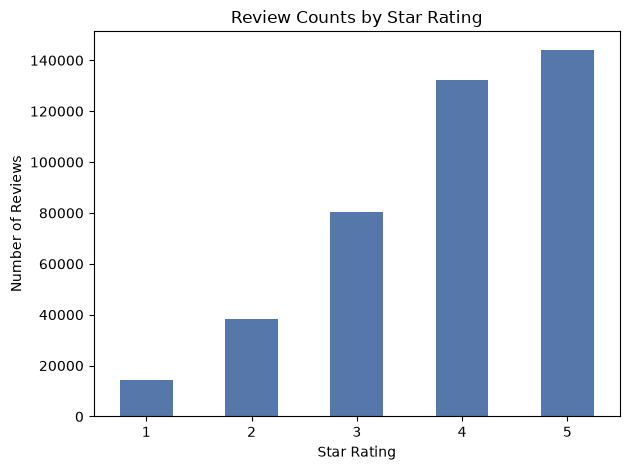

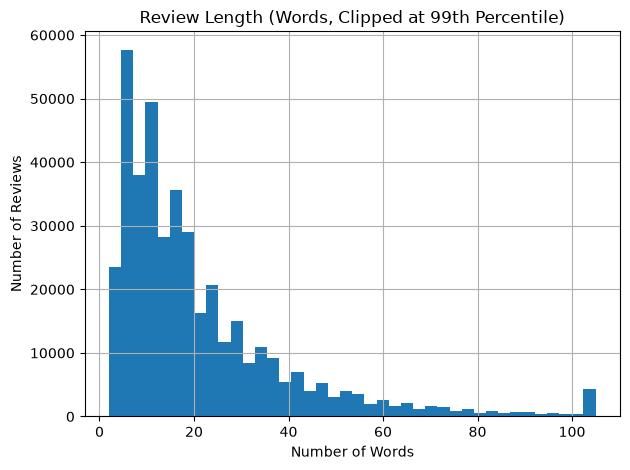

In [12]:
print("Dataset shape:", df.shape)

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_rows"))

print("Rating distribution:")
display(
    df["rating"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

df["text_length_chars"] = df["text"].fillna("").str.len()
df["text_length_words"] = df["text"].fillna("").str.split().str.len()

display(df[["text_length_chars", "text_length_words"]].describe().round(2))

df["rating"].value_counts().sort_index().plot(
    kind="bar",
    color="#5577aa"
)
plt.title("Review Counts by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

df["text_length_words"].clip(
    upper=df["text_length_words"].quantile(0.99)
).hist(bins=40)

plt.title("Review Length (Words, Clipped at 99th Percentile)")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

## 3. Text Cleaning and Label Creation

The text cleaning process is conservative. It removes URLs, HTML tags, Arabic diacritics, and tatweel, and normalizes variations of Alef and Yeh. Negation words such as “لا” and “مش” are preserved because they can change the meaning of a review.

In [13]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
HTML_RE = re.compile(r"<[^>]+>")
DIACRITICS_RE = re.compile(r"[\u064B-\u065F\u0670\u06D6-\u06ED]")

def clean_arabic_text(value):
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKC", text)
    text = URL_RE.sub(" ", text)
    text = HTML_RE.sub(" ", text)
    text = text.replace("ـ", "")
    text = DIACRITICS_RE.sub("", text)
    text = re.sub("[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي")
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["text"] = df["text"].map(clean_arabic_text)

rows_before = len(df)
df = df[df["text"].str.len() > 0].copy()
print(f"Empty reviews removed: {rows_before - len(df):,}")

def rating_to_label(rating):
    if rating in (1, 2):
        return 0
    if rating == 3:
        return 1
    return 2

df["label"] = df["rating"].map(rating_to_label).astype("int64")

print("Label mapping:", LABEL_MAP)
display(df[["rating", "label", "text"]].head(10))
display(df["label"].map(LABEL_MAP).value_counts().to_frame("count"))

Empty reviews removed: 0
Label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}


,rating,label,text
0,4,2,“فندق راقي وسوف تتكرر زيارتي له”. الفندق بصراح...
1,2,0,“ممتاز”. النظافة والطاقم متعاون.
2,5,2,استثنائي. سهولة انهاء المعاملة في الاستقبال. ل...
3,4,2,جيد جدا. 😊👍. لايوجد
4,5,2,“الحمدلله رب العالمين كان يوم جميل قضيناه في ا...
5,5,2,“فندق رائع”. الفندق مميز بموقعه و تصميمه و ديك...
6,3,1,مرضي. . حمام السباحه لايعمل و الاضاءه في الغرف...
7,5,2,“اقامة رائعة”. . ح
8,4,2,“المره هذه تقييمي له جيد.”. . اعجبني النظافة و...
9,5,2,استثنائي. الفندق نظيف والغرفه وسيعه وحلوه وموق...


,count
label,
positive,276387
neutral,80326
negative,52849


## 4. Duplicate Reviews and Conflicting Labels

If the same review text appears with different labels, all copies of that text will be removed to avoid conflicting labels. For texts repeated with the same label, only one copy will be kept.

In [14]:
text_counts = df["text"].value_counts()
label_counts_per_text = df.groupby("text")["label"].nunique()

repeated_texts = text_counts[text_counts > 1]
conflicting_texts = label_counts_per_text[label_counts_per_text > 1]

print(f"Unique texts appearing more than once: {len(repeated_texts):,}")
print(f"Extra repeated rows: {len(df) - df['text'].nunique():,}")
print(f"Texts associated with conflicting labels: {len(conflicting_texts):,}")
print(
    "Rows with conflicting labels:",
    int(df["text"].isin(conflicting_texts.index).sum())
)

if len(conflicting_texts) > 0:
    display(
        df[df["text"].isin(conflicting_texts.index)][
            ["rating", "label", "text"]
        ].head(10)
    )

Unique texts appearing more than once: 2,835
Extra repeated rows: 10,006
Texts associated with conflicting labels: 78
Rows with conflicting labels: 479


,rating,label,text
982,5,2,“ممتاز”. كل شي.
1501,5,2,“ممتاز”. كل شي.
2218,4,2,“ممتاز”. ممتاز.
2342,5,2,“ممتاز”. كل شي. لا شي
3351,3,1,“جيد”. كل شي. لاشي
3392,5,2,“ممتاز”. كل شي.
3796,5,2,“ممتازه”. كل شي ممتاز. لا شي
5681,3,1,“جيد”. الهدوء. المواقف
5826,4,2,“جيد”. جيد.
6040,5,2,“ممتاز”. كل شي ممتاز.


In [15]:
label_counts_per_text = df.groupby("text")["label"].nunique()
conflicting_texts = set(
    label_counts_per_text[label_counts_per_text > 1].index
)

conflict_rows = df["text"].isin(conflicting_texts)

print(f"Conflicting texts: {len(conflicting_texts):,}")
print(f"Rows removed due to conflicting labels: {int(conflict_rows.sum()):,}")

df = df.loc[~conflict_rows].copy()

rows_before_deduplication = len(df)
df = df.drop_duplicates(subset="text", keep="first").copy()

print(
    "Duplicate rows removed:",
    f"{rows_before_deduplication - len(df):,}"
)
print(f"Rows retained: {len(df):,}")

class_counts = df["label"].value_counts().sort_index()
class_counts.index = class_counts.index.map(LABEL_MAP)
display(class_counts.to_frame("count"))

Conflicting texts: 78
Rows removed due to conflicting labels: 479
Duplicate rows removed: 9,605
Rows retained: 399,478


,count
label,
negative,52113
neutral,79439
positive,267926


## 5. Train / Validation / Test Split

The data is split into training, validation, and test sets using an 80/10/10 ratio. Stratification is applied to preserve the class distribution as closely as possible. The test set will not be used to select training settings.

In [16]:
train_df, temp_df = train_test_split(
    df,
    test_size=TEST_SIZE + VALIDATION_SIZE,
    random_state=SEED,
    stratify=df["label"],
)

relative_test_size = TEST_SIZE / (TEST_SIZE + VALIDATION_SIZE)

val_df, test_df = train_test_split(
    temp_df,
    test_size=relative_test_size,
    random_state=SEED,
    stratify=temp_df["label"],
)

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    print(f"{split_name}: {len(split_df):,} rows ({len(split_df) / len(df):.1%})")

    class_proportions = (
        split_df["label"]
        .map(LABEL_MAP)
        .value_counts(normalize=True)
        .rename("proportion")
        .to_frame()
    )
    display(class_proportions)

model_columns = ["text", "label", "rating"]

train_df[model_columns].to_csv(
    processed_dir / "train.csv",
    index=False,
    encoding="utf-8",
)

val_df[model_columns].to_csv(
    processed_dir / "validation.csv",
    index=False,
    encoding="utf-8",
)

test_df[model_columns].to_csv(
    processed_dir / "test.csv",
    index=False,
    encoding="utf-8",
)

print("Saved the split files to:", processed_dir)

train: 319,582 rows (80.0%)


,proportion
label,
positive,0.670692
neutral,0.198857
negative,0.130452


validation: 39,948 rows (10.0%)


,proportion
label,
positive,0.670697
neutral,0.198859
negative,0.130445


test: 39,948 rows (10.0%)


,proportion
label,
positive,0.670672
neutral,0.198859
negative,0.130470


Saved the split files to: E:\ANN\ANN_01\data\processed


## 6. Converting Text into Numbers

CountVectorizer learns the vocabulary from the training set only, then transforms all three sets into binary sparse matrices. This reduces storage requirements compared with dense matrices. Text representation is an additional preprocessing step beyond the concepts covered in the two lab sections.

In [17]:
vectorizer = CountVectorizer(
    max_features=MAX_FEATURES,
    binary=True,
    token_pattern=r"(?u)\b\w+\b",
    lowercase=False,
)

X_train = vectorizer.fit_transform(train_df["text"])
X_validation = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

save_npz(processed_dir / "X_train.npz", X_train)
save_npz(processed_dir / "X_validation.npz", X_validation)
save_npz(processed_dir / "X_test.npz", X_test)

joblib.dump(vectorizer, processed_dir / "count_vectorizer.joblib")

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Train:", X_train.shape, "| non-zero values:", f"{X_train.nnz:,}")
print("Validation:", X_validation.shape, "| non-zero values:", f"{X_validation.nnz:,}")
print("Test:", X_test.shape, "| non-zero values:", f"{X_test.nnz:,}")

Vocabulary size: 8000
Train: (319582, 8000) | non-zero values: 5,538,415
Validation: (39948, 8000) | non-zero values: 693,155
Test: (39948, 8000) | non-zero values: 697,996


In [18]:
summary = {
    "source_file": str(raw_path),
    "raw_rows_loaded": int(len(records)),
    "malformed_rows_skipped": int(bad_lines),
    "rows_after_cleaning_and_deduplication": int(len(df)),
    "split_sizes": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "class_mapping": {
        str(label_id): label_name
        for label_id, label_name in LABEL_MAP.items()
    },
    "class_counts": {
        LABEL_MAP[int(label_id)]: int(count)
        for label_id, count in df["label"].value_counts().items()
    },
    "vectorizer": {
        "type": "CountVectorizer",
        "binary": True,
        "max_features": MAX_FEATURES,
        "vocabulary_size": int(len(vectorizer.vocabulary_)),
    },
    "random_seed": SEED,
}

summary_path = processed_dir / "dataset_summary.json"

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("All outputs are saved in:", processed_dir)

for path in sorted(processed_dir.iterdir()):
    print(f"- {path.name} ({path.stat().st_size / (1024 ** 2):.2f} MB)")

All outputs are saved in: E:\ANN\ANN_01\data\processed
- count_vectorizer.joblib (0.25 MB)
- dataset_summary.json (0.00 MB)
- test.csv (9.11 MB)
- train.csv (72.14 MB)
- validation.csv (9.06 MB)
- X_test.npz (1.22 MB)
- X_train.npz (10.03 MB)
- X_validation.npz (1.21 MB)


## Outputs

- `train.csv`, `validation.csv`, and `test.csv`: cleaned review texts and labels.
- `X_train.npz`, `X_validation.npz`, and `X_test.npz`: sparse Bag-of-Words representations.
- `count_vectorizer.joblib`: the fitted text vectorizer for transforming new reviews.
- `dataset_summary.json`: dataset counts and preprocessing settings.

The notebook expects the dataset to be located at the path specified above.